## 1: Introdução

---

### 1.1. Contextualização

Durante nossas pesquisas no projeto 1, vimos que uma aplicação dos modelos de Naive Bayes é de análise de sentimentos em textos corridos. Por exemplo, um modelo de Naive Bayes pode usar da contagem de palavras em cada texto para determinar se um tweet tem conotação positiva ou negativa por parte do usuário, como foi feito na Indonésia durante o ínicio da pandemia COVID-19.

Com base nisso, o problema sobre o qual decidimos nos debruçar é o de classificar o sentimento de resenhas de filmes como positivo ou negativo.


### 1.2. Objetivo

Nosso objetivo principal é por esse algoritmo à prova nesse cenário de classificação de textos. Vimos nas nossas pesquisas para o projeto 1 que esse tipo de modelo é frequentemente aplicado nesse contexto, mas queremos entender qual é a performance que podemos esperar de um modelo treinado em um conjunto de dados suficientemente diverso.

Sabemos que o Naive Bayes classifica textos calculando apenas para a probabilidade de termos isolados, sem levar em consideração o contexto de uso desses termos. **Qual é o impacto dessa limitação na performance do modelo?**

### 1.3. Descrição dos Dados

O dataset que escolhemos para aplicar o modelo é chamado ["IMDB Dataset of 50K Movie Reviews"](https://www.kaggle.com/datasets/lakshmi25npathi/imdb-dataset-of-50k-movie-reviews), disponível no Kaggle. Ao que o criador do dataset indica, esse conjunto de dados é uma amostra de um conjunto de treino para processamento de linguagem natural da universidade de Stanford.

Como o nome afirma, é composto por 50 mil exemplos de resenhas de filmes desconhecidos, todos eles rotulados com uma emoção, positivo ou negativo. Cada amostra é composta por apenas esses dois valores, rotulados como `review` e `sentiment` respectivamente. Vamos explorar os dados agora.

## 2: Análise Exploratória de Dados

---

### 2.1. Carregamento e Limpeza dos Dados

Vamos começar carregando o dataset (e algumas livrarias que vamos usar ao longo do projeto):

In [ ]:
options(repr.plot.bg = "white")

In [ ]:
install.packages(c("tm", "stringr"))
library(tm)
library(stringr)

dataset <- read.csv("data/IMDB Dataset.csv")

head(dataset, n = 2)

Installing packages into ‘/home/trinity/R/library’
(as ‘lib’ is unspecified)



,review,sentiment
,<chr>,<chr>
1,"One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with me.<br /><br />The first thing that struck me about Oz was its brutality and unflinching scenes of violence, which set in right from the word GO. Trust me, this is not a show for the faint hearted or timid. This show pulls no punches with regards to drugs, sex or violence. Its is hardcore, in the classic use of the word.<br /><br />It is called OZ as that is the nickname given to the Oswald Maximum Security State Penitentary. It focuses mainly on Emerald City, an experimental section of the prison where all the cells have glass fronts and face inwards, so privacy is not high on the agenda. Em City is home to many..Aryans, Muslims, gangstas, Latinos, Christians, Italians, Irish and more....so scuffles, death stares, dodgy dealings and shady agreements are never far away.<br /><br />I would say the main appeal of the show is due to the fact that it goes where other shows wouldn't dare. Forget pretty pictures painted for mainstream audiences, forget charm, forget romance...OZ doesn't mess around. The first episode I ever saw struck me as so nasty it was surreal, I couldn't say I was ready for it, but as I watched more, I developed a taste for Oz, and got accustomed to the high levels of graphic violence. Not just violence, but injustice (crooked guards who'll be sold out for a nickel, inmates who'll kill on order and get away with it, well mannered, middle class inmates being turned into prison bitches due to their lack of street skills or prison experience) Watching Oz, you may become comfortable with what is uncomfortable viewing....thats if you can get in touch with your darker side.",positive
2,"A wonderful little production. <br /><br />The filming technique is very unassuming- very old-time-BBC fashion and gives a comforting, and sometimes discomforting, sense of realism to the entire piece. <br /><br />The actors are extremely well chosen- Michael Sheen not only ""has got all the polari"" but he has all the voices down pat too! You can truly see the seamless editing guided by the references to Williams' diary entries, not only is it well worth the watching but it is a terrificly written and performed piece. A masterful production about one of the great master's of comedy and his life. <br /><br />The realism really comes home with the little things: the fantasy of the guard which, rather than use the traditional 'dream' techniques remains solid then disappears. It plays on our knowledge and our senses, particularly with the scenes concerning Orton and Halliwell and the sets (particularly of their flat with Halliwell's murals decorating every surface) are terribly well done.",positive


Notamos de cara que o texto precisa ser tratado extensivamente, mas deixaremos isso para mais tarde.

Agora vamos verificar a situação geral dos dados usando a função `summary` para nos informar quantos elementos há no total, quantas duplicatas possuímos e quantos dados faltantes temos:

In [ ]:
summary(dataset)

    review           sentiment        
 Length:50000       Length:50000      
 Class :character   Class :character  
 Mode  :character   Mode  :character  

Vemos que **não existem dados faltantes** felizmente, uma vez que `N.blank = 0`.

No entanto, podemos ver que nem todas as resenhas são únicas; em especial, apenas `49582` são únicas, restando `418` duplicatas. Para prevenir o enviesamento do modelo de Bayes (que é sensível a duplicatas), decidimos remover esses valores, uma vez que o conjunto é grande o suficiente para que uma perda pequena de dados não traga consequências significativas ao desempenho do algoritmo.

In [ ]:
dataset <- dataset[!duplicated(dataset), ]

summary(dataset)

    review           sentiment        
 Length:49582       Length:49582      
 Class :character   Class :character  
 Mode  :character   Mode  :character  

Além das duplicatas, o `head` lá em cima já mostra outro problema: há pedaços de HTML misturados ao texto (como `<br /><br />`). Vamos medir quanto da base tem cada tipo de sujeira

In [ ]:
# fração das resenhas com a tag <br />
mean(grepl("<br", dataset$review))

# outras tags HTML além do <br />
sum(grepl("<[a-zA-Z]+[^>]*>", gsub("<br\\s*/?>", "", dataset$review)))

# resenhas com links
sum(grepl("http|www\\.", dataset$review))

[1] 0.5842039

[1] 10

[1] 203

mais ou menos 58% das reviews têm `<br/>`. Se a gente não tirar, depois de remover a pontuação sobra a "palavra" `br`, que seria uma das mais frequentes do corpus e n significa nada
- poucas reviews têm outras tags html
- uns 200 têm links

### 2.2. Análise Univariada

Vamos ir analisamos cada variável separadamente, incialmente,pela variável-alvo


negative positive 
   24698    24884 


 negative  positive 
0.4981243 0.5018757 

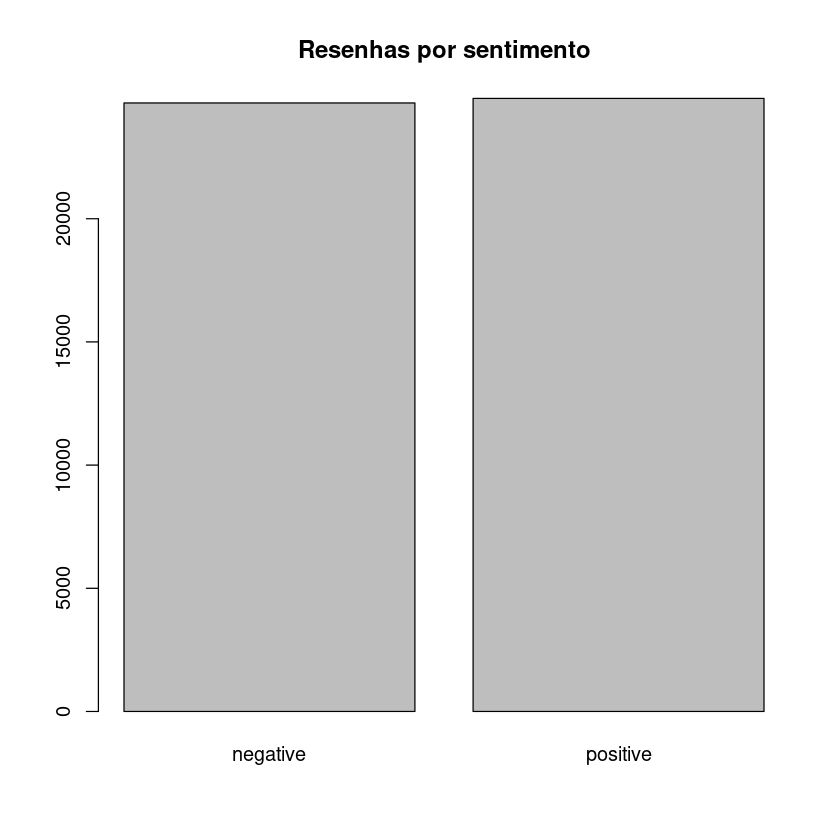

In [ ]:
table(dataset$sentiment)
prop.table(table(dataset$sentiment))

barplot(table(dataset$sentiment), main = "Resenhas por sentimento")

as classes estão praticamente balanceadas. isso é bom, pq a acurácia se torna uma métrica honesta para avaliar o modelo e e as probabilidades a priori do Naive Bayes ficam próximas de 0,5

#### Tamanho das resenhas

Como o dataset só tem a resenha e o rótulo, vamos criar algumas medidas a partir do texto. A primeira é o número de palavras de cada resenha:

In [8]:
# contagem de palavras ignorando as tags HTML (senão cada <br /> contaria como palavra)
dataset$n_words <- lengths(strsplit(gsub("<[^>]+>", " ", dataset$review), "\\s+"))

summary(dataset$n_words)
quantile(dataset$n_words, c(0.01, 0.05, 0.95, 0.99))

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
    4.0   125.0   172.0   229.1   278.0  2459.0 

1%     5%    95%    99% 
 41.00  62.05 585.00 897.00

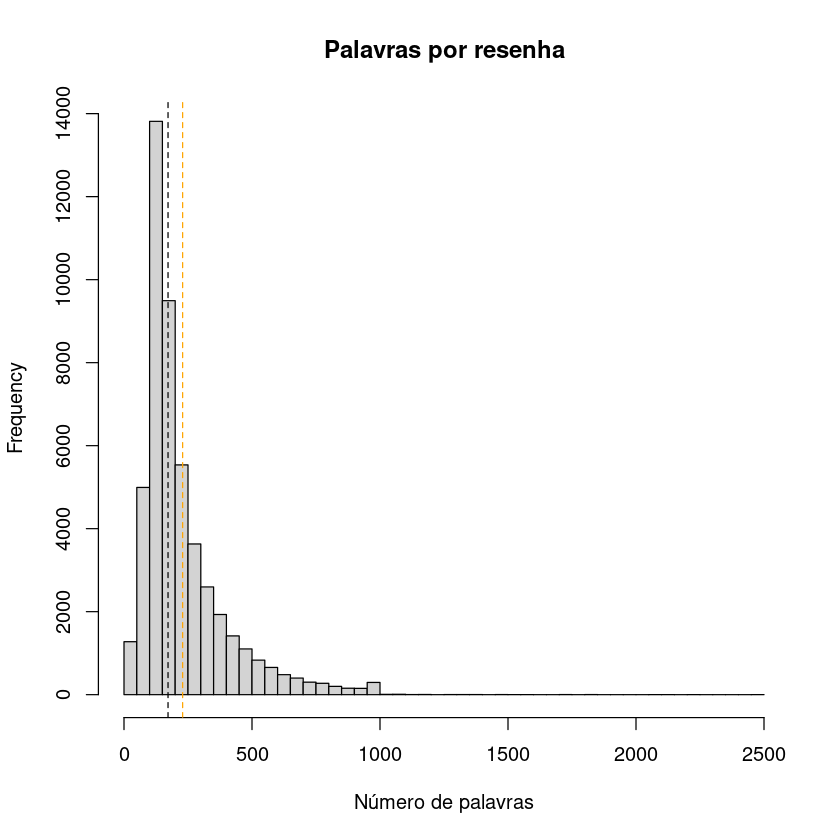

In [9]:
hist(dataset$n_words, breaks = 80, main = "Palavras por resenha", xlab = "Número de palavras")
abline(v = c(median(dataset$n_words), mean(dataset$n_words)), col = c("black", "orange"), lty = 2)  # mediana (preta) e média (laranja)

a distribuição é bem assimétrica à direita, a maior parte das resenhas tem entre 120 e 270 palavras, mas há uma cauda longa de textos enormes, o que puxa a média para cima da mediana. Por isso, a mediana representa melhor o tamanho típico de uma resenha

#### Pontuação e palavras em maiúsculo

Algumas características de estilo podem indicar emoção na escrita. Vamos medir a presença de exclamação, interrogação e palavras inteiras em maiúsculo

In [10]:
# fração de resenhas com pelo menos um "!" e com pelo menos um "?"
mean(grepl("!", dataset$review))
mean(grepl("\\?", dataset$review))

# palavras inteiras em maiúsculo(2+)
dataset$n_upper <- stringr::str_count(dataset$review, "\\b[A-Z]{2,}\\b")
table(cut(dataset$n_upper, c(-1, 0, 1, 3, 10, Inf), labels = c("0", "1", "2-3", "4-10", "> 10")))

[1] 0.3469203

[1] 0.2958533


    0     1   2-3  4-10  > 10 
25600 10146  7655  4830  1351 

achamos que exclamações, interrogações e palavras em maiúsculo são marcas de 'emoção' na escrita, então medimos o quanto elas são comuns. Cerca de 35% das resenhas têm pelo menos uma exclamação e 30% têm pelo menos uma interrogação, ou seja, são recursos frequentes e não casos isolados

#### Notas explícitas no texto

vi que muitas pessoas escrevem a própria nota, tipo "7/10". Vamos ver quantas fazem isso e como essas notas se distribuem

[1] 2941

[1] 0.05931588

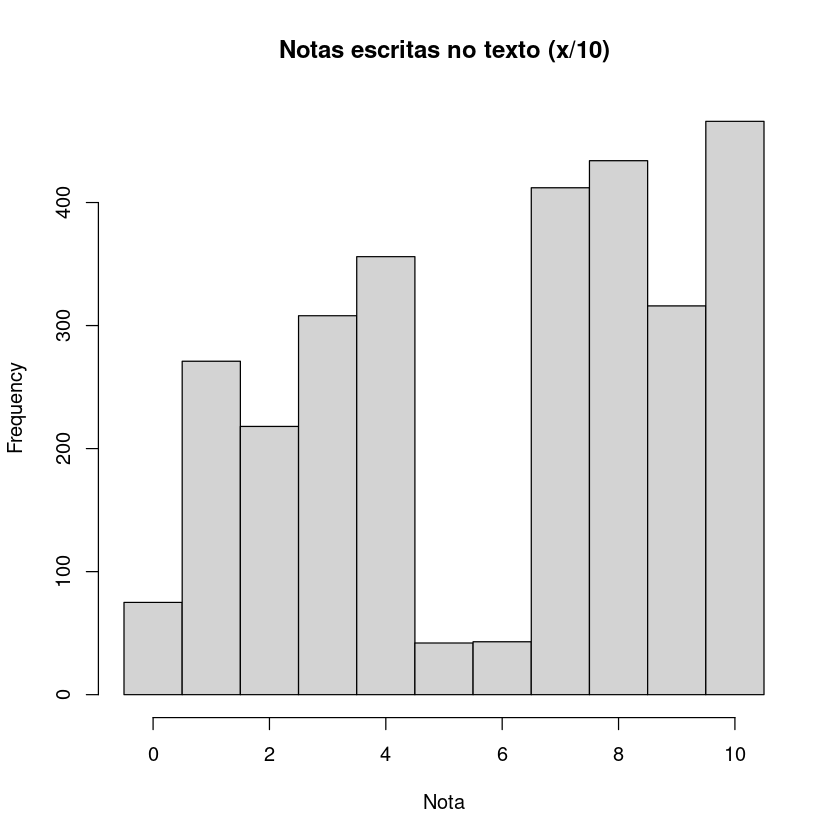

In [11]:
padrao_nota <- "\\b(10|[0-9])(\\.[0-9])?\\s*/\\s*10\\b"

dataset$has_rating <- grepl(padrao_nota, dataset$review)
dataset$rating <- NA
dataset$rating[dataset$has_rating] <- as.numeric(sub("\\s*/.*", "", regmatches(dataset$review, regexpr(padrao_nota, dataset$review))))

sum(dataset$has_rating)
mean(dataset$has_rating)

hist(dataset$rating, breaks = -0.5:10.5, main = "Notas escritas no texto (x/10)", xlab = "Nota")

Cerca de 6% das resenhas trazem uma nota no formato "x/10". essa nota funciona quase como o próprio rótulo escrito no texto, só que como já temos rótulo, essa nota não irá fazer tanta diferença

### 2.3. Análise Bivariada e Multivariada

Agora vamos ver se as variáveis que criamos na análise univariada têm alguma relação com o sentimento

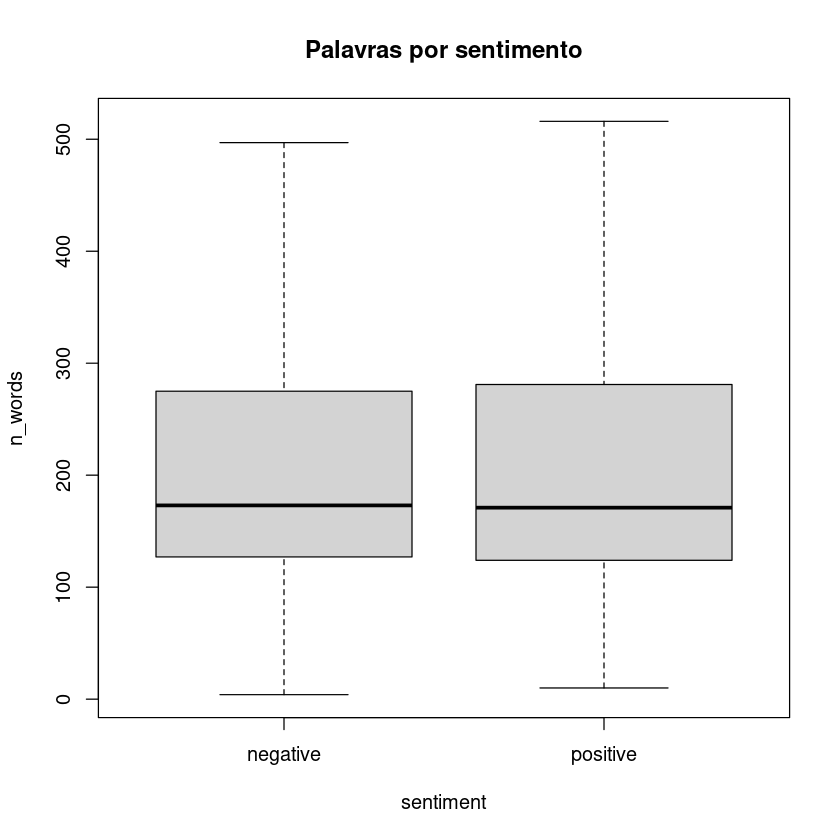

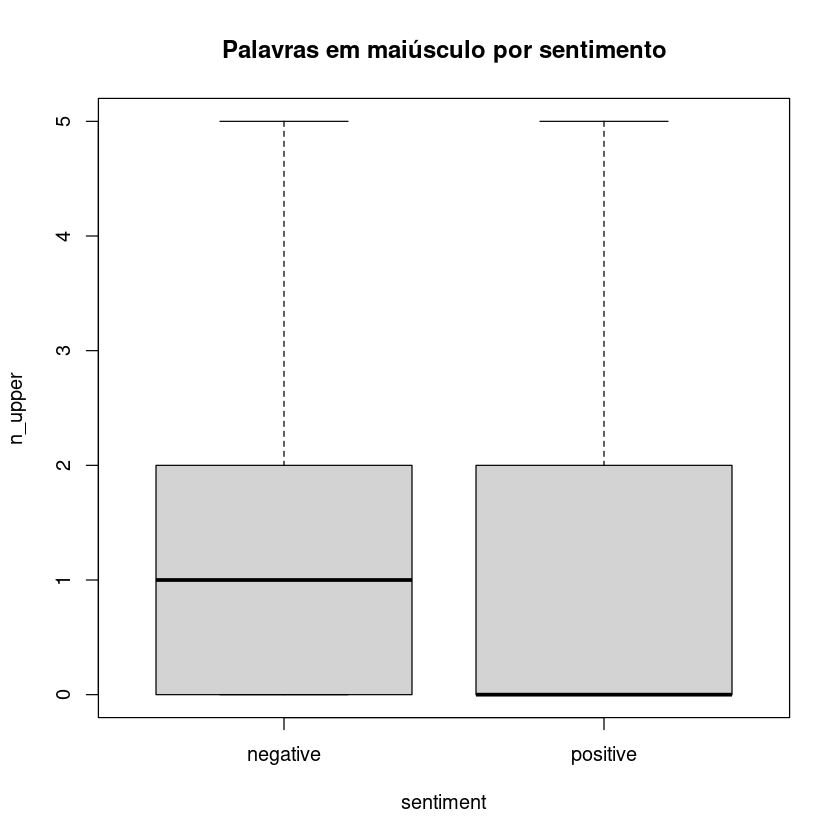

In [12]:
boxplot(n_words ~ sentiment, data = dataset, outline = FALSE, main = "Palavras por sentimento")
boxplot(n_upper ~ sentiment, data = dataset, outline = FALSE, main = "Palavras em maiúsculo por sentimento")

o número de palavras quase não muda entre sentimentos (mediana de 171 a 173) com quase 50 mil linhas, até uma diferença mínima dá "significativa". já as maiúsculas têm uma diferença bem mais forte (p < 2e-16): resenhas negativas usam mais palavras em maiúsculo (mediana 1, contra 0 nas positivas), o que já é um indício a favor da hipótese b que testamos na seção 3.

In [13]:
# fração de resenhas com "!" e "?" por sentimento
sapply(c(exclamacao = "!", interrogacao = "\\?"), function(p) tapply(grepl(p, dataset$review), dataset$sentiment, mean))

chisq.test(table(grepl("!", dataset$review), dataset$sentiment))
chisq.test(table(grepl("\\?", dataset$review), dataset$sentiment))


,exclamacao,interrogacao
negative,0.354887,0.3773180
positive,0.339013,0.2149976



	Pearson's Chi-squared test with Yates' continuity correction

data:  table(grepl("!", dataset$review), dataset$sentiment)
X-squared = 13.716, df = 1, p-value = 0.0002126



	Pearson's Chi-squared test with Yates' continuity correction

data:  table(grepl("\\?", dataset$review), dataset$sentiment)
X-squared = 1566.9, df = 1, p-value < 2.2e-16


a exclamação quase não varia entre os sentimentos (35% nas negativas, 34% nas positivas). mas a interrogação sim: 38% das negativas tem "?" contra só 21% das positivas. talvez as pessoas façam mais perguntas retóricas ("por que fizeram isso com esse filme?") quando não gostaram.

#### Nota explícita e sentimento

In [14]:
tapply(dataset$rating, dataset$sentiment, mean, na.rm = TRUE)

cor.test(dataset$rating, as.integer(factor(dataset$sentiment)), method = "spearman")


negative positive 
2.926546 8.401672

Warning message in cor.test.default(dataset$rating, as.integer(factor(dataset$sentiment)), :
“Cannot compute exact p-value with ties”



	Spearman's rank correlation rho

data:  dataset$rating and as.integer(factor(dataset$sentiment))
S = 818326352, p-value < 2.2e-16
alternative hypothesis: true rho is not equal to 0
sample estimates:
      rho 
0.8069842 


quem escreve a nota no texto, a nota bate muito com o rótulo: média de 2.9 nas negativas e 8.4 nas positivas, com correlação de 0.81. faz sentido, o rótulo do próprio dataset provavelmente foi derivado dessa nota em primeiro lugar (reviews do IMDb com nota <= 4 são marcadas como negativas e >= 7 como positivas).

#### Visão conjunta

,n_words,n_upper,has_excl,has_quest,positive
n_words,1.00,0.29,0.11,0.26,-0.01
n_upper,0.29,1.00,0.20,0.17,-0.07
has_excl,0.11,0.20,1.00,0.15,-0.02
has_quest,0.26,0.17,0.15,1.00,-0.18
positive,-0.01,-0.07,-0.02,-0.18,1.00


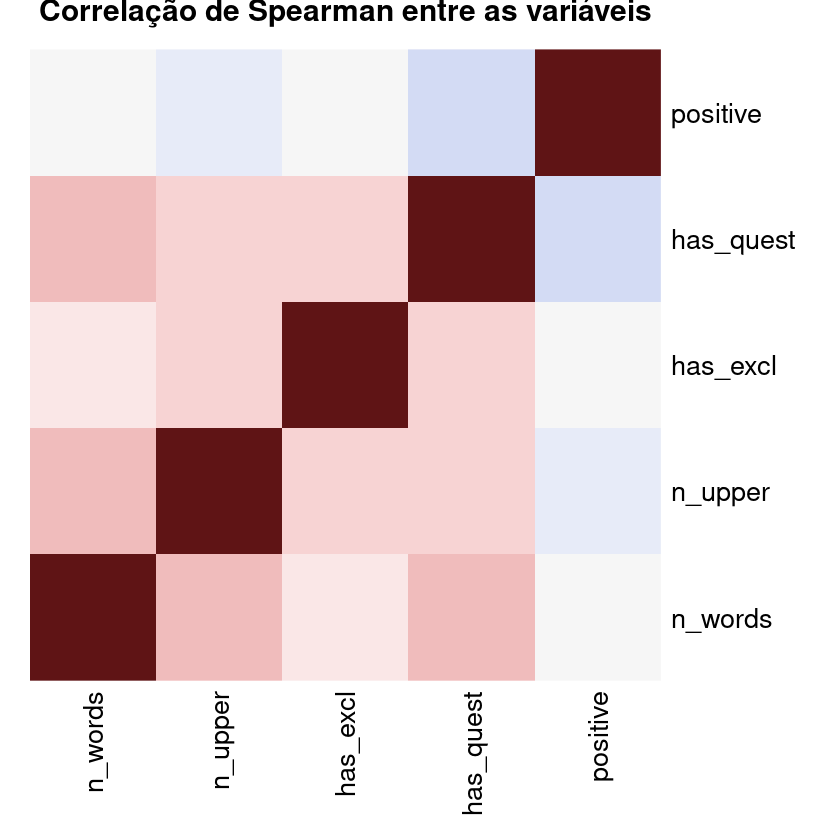

In [15]:
# correlação de Spearman entre as variáveis da EDA e o sentimento
cor_mat <- cor(data.frame(
  n_words   = dataset$n_words,
  n_upper   = dataset$n_upper,
  has_excl  = grepl("!", dataset$review),
  has_quest = grepl("\\?", dataset$review),
  positive  = dataset$sentiment == "positive"
), method = "spearman")

round(cor_mat, 2)

# mapa de calor: vermelho = correlação positiva, azul = negativa, branco = perto de 0
heatmap(cor_mat, Rowv = NA, Colv = NA, scale = "none", margins = c(8, 8),
        col = hcl.colors(21, "Blue-Red 3"), zlim = c(-1, 1),
        main = "Correlação de Spearman entre as variáveis")

nenhuma dessas variáveis, sozinha, tem uma relação forte com o sentimento. A correlação mais alta em módulo é a da presença de interrogação e mesmo ela é fraca

#### Palavras associadas a cada sentimento


vamos olhar direto para as palavras, que é o que o naive bayes usa. para cada palavra, calculamos o log de quantas vezes a palavra aparece mais num sentimento do que no outro: perto de 0, a palavra é neutra; positivo, aparece mais nas positivas; negativo, mais nas negativas

consideramos só palavras com pelo menos 500 ocorrências. abaixo disso, o topo do gráfico fica cheio de nomes de filmes e atores que aparecem quase sempre num tipo de resenha só


In [16]:
# Gráfico das palavras mais associadas a cada sentimento
#n:quantas palavras mostrar de cada lado
grafico_log_razao <- function(palavras, sentimento, min_freq = 500, n = 15, titulo = "") {
  vocab <- unique(unlist(palavras))
  V <- length(vocab)

  # qnts vezes cada palavra aparece nas resenhas positivas e nas negativas
  pos <- table(factor(unlist(palavras[sentimento == "positive"]), levels = vocab))
  neg <- table(factor(unlist(palavras[sentimento == "negative"]), levels = vocab))

  #mede 'quantas vezes mais" a palavra aparece num lado)
  log_razao <- log((pos + 1) / (sum(pos) + V)) - log((neg + 1) / (sum(neg) + V))

  # tira palavras raras + ordena
  log_razao <- sort(log_razao[pos + neg >= min_freq])

  # as n mais negativas e as n mais positivas
  extremos <- c(head(log_razao, n), tail(log_razao, n))

  par(mar = c(5, 8, 4, 2))  # sómargem esquerda maior para caber os nomes
  barplot(extremos, horiz = TRUE, las = 1, cex.names = 0.7,
          col = ifelse(extremos > 0, "#00798C", "#D1495B"),
          main = titulo, xlab = "log P(palavra | pos) - log P(palavra | neg)")

  invisible(log_razao)
}

# separa cada resenha em palavras (minúsculas, sem HTML, quebrando em tudo que não é letra)
texto <- tolower(gsub("<[^>]+>", " ", dataset$review))
palavras_eda <- strsplit(texto, "[^a-z']+")

# o strsplit gera alguns "" (pedaços vazios) quando há dois separadores seguidos,ai tiramos só esses
palavras_eda <- lapply(palavras_eda, function(p) p[p != ""])

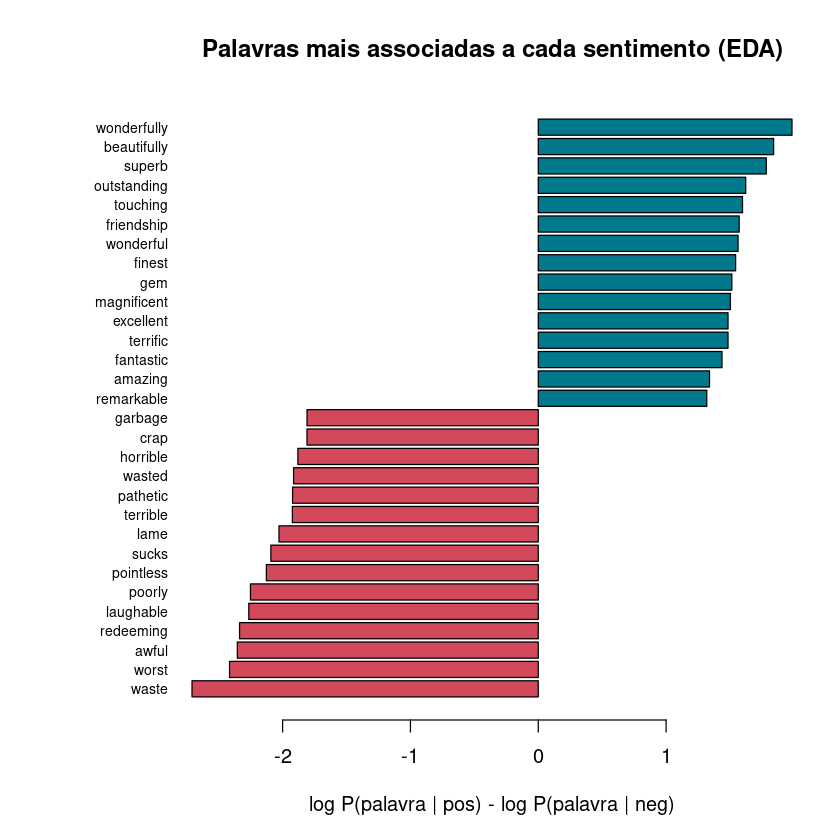

In [17]:
razao_eda <- grafico_log_razao(palavras_eda, dataset$sentiment,
                               titulo = "Palavras mais associadas a cada sentimento (EDA)")

do lado negativo aparecem palavras como waste, worst, awful e laughable, e do lado positivo, wonderfully, beautifully, superb e outstanding. as negativas têm valores mais extremos: waste, por exemplo, aparece cerca de 15 vezes mais em resenhas negativas, enquanto a positiva mais forte aparece cerca de 7 vezes mais nas positivas. ou seja, quem não gostou do filme costuma usar palavras mais 'carregadas'

### 2.4. Insights

- as classes estão balanceadas (quase 50/50) e não há dados faltantes, mas havia 418 duplicatas, que já removemos;
- boa parte das resenhas (58%) tem a tag `<br />`, que precisa ser limpa antes de contar palavras;
- o tamanho das resenhas é bem assimétrico à direita (mediana ~170 palavras, com uma cauda de textos bem maiores), mas isso praticamente não muda entre sentimentos;
- palavras em maiúsculo e, principalmente, pontos de interrogação aparecem mais em resenhas negativas — um indício de que o texto carrega sinais de sentimento além do vocabulário em si;
- a nota explícita ("x/10"), quando presente, bate fortemente com o rótulo, o que é esperado já que o próprio rótulo provavelmente vem dessa nota;
- nenhuma dessas métricas isoladas é um bom preditor por si só, então faz sentido seguir para um modelo que considera o texto inteiro (Naive Bayes nas próximas seções).

## 3: Validação Estatística

---

### 3.1. Definição das Hipóteses

Vamos escolher duas hipóteses da nossa apresentação passada. Queremos testar se:

**a.** Resenhas que mencionam termos como "sequels" ou "remakes" são *geralmente* mais negativas que resenhas quaisquer;

**b.** Resenhas negativas *geralmente* usam mais palavras em MAIÚSCULO e pontos de exclamação que resenhas positivas.

Precisamos primeiramente converter essas hipóteses para uma linguagem que nos permita entender quais medidas queremos testar.
  - Considere que a coluna `sentiment` se refere a um valor numérico binário, isto é, `negative` se refere ao número 0 e `positive`, ao número 1.
  - Seja $\overline{x}$ a porcentagem de resenhas positivas no conjunto. Isso é equivalente à media da coluna `sentiment` se a interpretarmos dessa forma.
  - Ademais, seja $\overline{c}_+$ a contagem média de palavras em maiúsculo e pontos de exclamação em resenhas positivas, e $\overline{c}_-$ a contagem em resenhas negativas.

**Para testar a hipótese a:** devemos testar se a porcentagem de resenhas positivas que mencionam continuações/remakes, $\overline{x}'$, é *menor* que $\overline{x}$.
  - Hipótese nula: $H_0 = \overline{x}' \ge \overline{x} \therefore \overline{x}' - \overline{x} \ge 0$
  - Hipótese alternativa: $H_a = \overline{x}' - \overline{x} \lt 0$

**Para testar a hipótese b:** devemos testar se a média de palavras em maiúsculo/pontos de exclamação em resenhas negativas é *maior* que em resenhas positivas.
  - Hipótese nula: $H_0 = \overline{c}_- \le \overline{c}_+ \therefore \overline{c}_- - \overline{c}_+ \le 0$
  - Hipótese alternativa: $H_a = \overline{c}_- - \overline{c}_+ \gt 0$


Antes de executarmos os testes, precisamos definir uma forma de transformar a coluna `sentiment` (que é categórica) em valores 0 ou 1, como dito anteriormente.

Para isso, criamos uma função (que será útil para pré-processamento dos dados pro modelo):

In [18]:
turn_sentiment_to_num <- function(sentiment) {
  # atribui o mesmo numero pra cada valor distinto
  sentiment_factor <- factor(sentiment)

  # (-1) pra ficar como 0 ou 1 (e não 1 ou 2)
  as.integer(sentiment_factor) - 1
}

dataset$sentiment_num <- turn_sentiment_to_num(dataset$sentiment)

Além disso, vamos usar como convenção um nível de confiança $\alpha = 95\%$:

In [19]:
alpha <- 0.95

### 3.2. Escolha a Execução do Teste

Como estamos lidando com médias e não sabemos as médias amostrais e variâncias das variáveis que usamos nas hipóteses, optamos pelo teste *t-Student*.

**Para testar a hipótese a**, primeiro, criemos uma função que verifique quais amostras na tabela são de resenhas que se referem a continuações ou remakes. Como não temos disponíveis os metadados dos filmes resenhados, uma aproximação disso é verificar se a resenha *menciona* de alguma forma, "sequel" ou "remake".

In [20]:
is_sequel_or_remake_review <- function(reviews) {
  as.integer(grepl("sequel|remake", reviews, perl = TRUE))
}

dataset$is_sequel_or_remake <- is_sequel_or_remake_review(dataset$review)

Feito isso, executemos os testes:

In [21]:
sequel_remake_sentiment <- dataset[dataset$is_sequel_or_remake == 1, "sentiment_num"]
sentiment_elsewhere <- dataset[dataset$is_sequel_or_remake == 0, "sentiment_num"]

t.test(
  x = sequel_remake_sentiment,
  y = sentiment_elsewhere,
  conf.level = alpha,
  alternative = "less"
)


	Welch Two Sample t-test

data:  sequel_remake_sentiment and sentiment_elsewhere
t = -11.137, df = 2538.1, p-value < 2.2e-16
alternative hypothesis: true difference in means is less than 0
95 percent confidence interval:
        -Inf -0.09905322
sample estimates:
mean of x mean of y 
0.3910396 0.5072648 


**Para a hipótese b**, vamos fazer a mesma coisa: vamos criar uma função que extraia a medida desejada, no caso, que conta a quantidade de palavras em maiúsculo e pontos de exclamação em cada resenha.

In [22]:
count_rage <- function(reviews) {
  # regex: qualquer palavra maiúscula do ínicio ao fim (\b[A-Z]{2,}\b)
  #        com no mínimo 2 caracteres (pra não pegar "A" e "I")
  #     OU qualquer sequência de pontos de exclamação (!, !!, !!!...)
  stringr::str_count(reviews, "\\b[A-Z]{2,}\\b|!+")
}

dataset$rage_count <- count_rage(dataset$review)

Executemos o teste:

In [23]:
negative_rage <- dataset[dataset$sentiment_num == 0, "rage_count"]
positive_rage <- dataset[dataset$sentiment_num == 1, "rage_count"]

t.test(
  x = negative_rage,
  y = positive_rage,
  conf.level = alpha,
  alternative = "greater"
)


	Welch Two Sample t-test

data:  negative_rage and positive_rage
t = 7.8075, df = 49578, p-value = 2.973e-15
alternative hypothesis: true difference in means is greater than 0
95 percent confidence interval:
 0.2700806       Inf
sample estimates:
mean of x mean of y 
 2.588793  2.246624 


### 3.3. Interpretação dos p-valores

**Para a hipótese a:** vemos que obtivemos um p-valor muito abaixo de $1 - \alpha = 0.05$, portanto, é muito improvável que uma amostragem aleatória resulte num conjunto com médias mais "extremas" que esse; assim, é esperado que conjuntos tirados do universo de resenhas de filmes tenham resultados similares.
- Por conta disso, rejeitamos $H_0$: podemos concluir que há evidências estatísticas que comprovem que resenhas de continuações ou remakes *são* geralmente mais negativas que resenhas quaisquer.

**Para a hipótese b:** similarmente, o p-valor está muito abaixo do nível de significância, sendo igual a $1.902 \times 10^{-13}$.
- Novamente, rejeitamos $H_0$: resenhas negativas usam uma quantidade significantemente maior de palavras em maiúsculo e pontos de exclamação que resenhas positivas em média.

## 4: Pré-processamento e Aplicação da Técnica

---

### 4.1. Preparação dos Dados para o Modelo:

Como vimos anteriormente, o texto precisa ser tratado para garantir a qualidade do significado das palavras a serem usadas na contagem para o algoritmo do Naive Bayes. 

Em outras palavras, precisamos garantir que as palavras com as quais o modelo vai treinar têm um "motivo" para serem contabilizadas na contagem. Por exemplo, artigos e preposições como `the`, `on`, `at`, `in` não adicionam muito ao significado do texto, mas sim servem para conectar ideias relevantes. Esse tipo de palavra é chamado de **stop word**. 

Para além das stop words, vemos que alguns elementos HTML (notavelmente o `br`) estão presentes em algumas resenhas. Esses elementos não tem significado nenhum pois serviram apenas para formatação. Também vale a pena remover números no texto, que isoladamente não servem muito.

Ademais, a palavra `"bad"` tem o mesmo significado que `"bad,"` ou `"bad..."`, e a pontuação por si só não enriquece muito o texto para fins de classificação de sentimento. No entanto, note que aqui temos uma exceção que já testamos e vimos que tem impacto na forma do ponto de exclamação `!` (vide projeto 1) e, ainda nessa linha, queremos manter palavras que estão totalmente em maiúsculo e não são stop words.

Portanto, **para treinar o modelo**, iremos definir algumas funções que tratam o texto de uma resenha da seguinte forma:
- Removendo todas as stop words;
- pondo em minúsculo tudo que não estiver TOTALMENTE EM MAIÚSCULO;
- removendo toda a pontuação presente no texto exceto pelo ponto de exclamação;
- removendo os elementos HTML; e
- removendo os números no texto.

Essa transformação não será perfeita, pois não temos como prever erros de digitação dos resenhistas, por exemplo, mas tornará o treinamento do modelo mais enxuto.

In [24]:
# função auxiliar para criar mais stop words
totitle <- function(word) {
  paste(
    toupper(substring(word, 1, 1)),
    tolower(substring(word, 2)),
    sep = ""
  )
}

case_insensitive_stopwords <- function() {
  lowercase <- tm::stopwords("SMART") # i, me, myself...
  titlecase <- totitle(lowercase)     # I, Me, Myself...
  uppercase <- toupper(lowercase)     # I, ME, MYSELF...

  c(rbind(lowercase, titlecase, uppercase))
}

clean_reviews <- function(reviews) {
  stop_words <- case_insensitive_stopwords()

  reviews <- tm::removeNumbers(reviews)
  reviews <- tm::removeWords(reviews, stop_words)

  html <- "<\\w* \\/>" # <br /> e similares ...
  reviews <- gsub(html, " ", reviews, perl = TRUE)

  # removendo pontuação MAS mantendo o "!"
  # o regex é: um ou mais " # $ % & ' etc.
  punctuation_no_excl <- "[\"#$%&'\\()*+,\\-./:;<=>?@[\\]^_`{|}~]+"
  reviews <- gsub(punctuation_no_excl, " ", reviews, perl = TRUE)

  # SE a palavra do começo ao fim for composta por
  # 1 ou mais letras maiúsculas, ignore (?![A-Z]+\W)
  # Caso contrário, selecione tudo (\S*)
  not_uppercase_word <- "(?![A-Z]+\\W)(\\S*)"
  reviews <- gsub(not_uppercase_word, "\\L\\1", reviews, perl = TRUE)

  # separando os pontos de exclamação para poder
  # contar eles como uma "palavra" separada
  reviews <- gsub("!", " ! ", reviews)

  reviews
}

Vale citar que as stop words que escolhemos vem do pacote `tm`, e inclui alguns termos que podem talvez ter alguma relação com o tom dos textos, como "no", "not", "appreciate", "sensible"... Pode ser que esses termos tenham algum impacto, mas vamos optar pelo caminho mais simples e considerar todas essas palavras mais de 500 palavras.

In [25]:
c("appreciate", "sensible", "no", "not") %in% tm::stopwords("SMART")

length(tm::stopwords("SMART"))

[1] TRUE TRUE TRUE TRUE

[1] 571

Vamos testar essa função em uma resenha qualquer:

In [26]:
random_number <- sample(nrow(dataset), 1)

review <- dataset$review[random_number]
review

clean <- clean_reviews(review)
clean

[1] "I supposed I was actually expecting a Bollywood remake of \"The Fog\", from the title, but this is actually more of a Bollywood remake of \"I Know What You Did Last Summer\", with some elements of \"Scream\", kind of, sort of, and not a very good one either. Apart from a couple very entertaining song & dance numbers, this is pretty terrible. It's obviously got a decent budget & yet it's wasted on reheated leftovers that weren't that tasty to begin with. A young woman is threatened by a creepy guy to not enter a beauty contest, because he wants his sister to win (she, thankfully, doesn't look as creepy as her brother), but she enters anyway and wins, and of course the creepy guy comes after her, and is killed, after which comes a rousing game of \"hide the body\". Of course, the body disappears and no one seems to know why, but someone knows, and they're waiting for the end to reveal a ridiculous plot twist. Interspersed with all this tired rehash are a few nifty dance numbers, especially the celebratory dance number at the party for Simran, the girl who won the beauty contest...it's highly colorful, it's well done & downright fun, and utterly wasted in this terrible film. I would much rather watch an old Ramsay brothers movie than this piece of crap, although someone has deemed that these don't need to be made available, for the most part, which is a crime in itself. But not as big of a crime as this film. I took one for the team watching this one, so take my advice, don't bother. 2 out of 10."

[1] " supposed    expecting  bollywood remake    fog    title         bollywood remake         summer    elements   scream  kind   sort       good       couple  entertaining song   dance numbers    pretty terrible      decent budget     wasted  reheated leftovers    tasty  begin    young woman  threatened   creepy guy   enter  beauty contest      sister  win   thankfully     creepy   brother    enters   wins      creepy guy       killed      rousing game   hide  body      body disappears               waiting   end  reveal  ridiculous plot twist  interspersed    tired rehash    nifty dance numbers    celebratory dance number   party  simran   girl  won  beauty contest  highly colorful       downright fun   utterly wasted   terrible film      watch   ramsay brothers movie   piece  crap     deemed       made      part     crime       big   crime   film       team watching       advice   bother      "

Vemos que mantemos em boa parte as palavras com mais relevância para nossa tarefa, então podemos prosseguir e aplicar esse tratamento no restante dos dados:

In [ ]:
# demora um tempão
dataset$clean_review <- clean_reviews(dataset$review)

Por fim, vamos definir uma função para retornar as palavras de uma resenha em formato de vetor. Isso será importante na fase de modelagem.

In [ ]:
split_words <- function(texts) {
  strsplit(trimws(texts), "\\s+")
}

Antes de partir para a modelagem, vamos verificar o efeito da limpeza. Para isso, repetimos o gráfico de palavras associadas a cada sentimento da seção 2.3, mas agora com o texto tratado pela função `clean_reviews`.

As diferenças esperadas vêm das decisões de pré-processamento: a lista de stop words passa a ser a SMART, palavras totalmente em maiúsculo são mantidas separadas (`BAD` ≠ `bad`), o ponto de exclamação passa a contar como uma "palavra" e os números são removidos inclusive de dentro das palavras.

In [ ]:
# mesmas contas da seção 2.3 (função grafico_log_razao), mas com as resenhas já limpas pela clean_reviews
razao_pre <- grafico_log_razao(split_words(dataset$clean_review), dataset$sentiment,
                               titulo = "Palavras mais associadas a cada sentimento (após o pré-processamento)")

# como ficaram o "!" e algumas palavras de comparação
round(razao_pre[c("!", "good", "bad")], 2)

O resultado é praticamente o mesmo da seção 2.3: as 30 palavras do gráfico são as mesmas, e os valores mudam muito pouco (`waste` vai de −2,71 para −2,73; `wonderfully`, de 1,98 para 1,97). Só a ordem de algumas palavras muda levemente.

O ponto de exclamação, que agora conta como palavra, tem razão de −0,15: ele puxa levemente para o lado negativo, mas está longe de ser um dos termos mais fortes.

Isso indica que o pré-processamento **não muda quais palavras diferenciam os sentimentos**. O efeito principal dele é enxugar o vocabulário: com o mesmo corte de 500 ocorrências, passamos de 2.016 termos na EDA para 1.591 aqui, já que as stop words e os números saem da contagem. Para o modelo, isso significa menos termos irrelevantes, sem perder as palavras que realmente carregam sentimento.

### 4.2. Modelagem

Primeiramente, vamos dividir o conjunto de dados em um conjunto de treino e um conjunto de teste.

Não usaremos conjunto de validação por entendermos que a ideia do projeto não engloba a otimização dos chamados "hiperparâmetros" do modelo.

A separação dos dados será de 80% para treino e 20% para teste:

In [ ]:
set.seed(69420)

train_rows <- sample(nrow(dataset), 0.8 * nrow(dataset))
train <- dataset[train_rows, ]
test  <- dataset[-train_rows, ]

paste("Quantidade de amostras de treino:", nrow(train))
paste("Quantidade de amostras de teste:", nrow(test))

[1] "Quantidade de amostras de treino: 39665"

[1] "Quantidade de amostras de teste: 9917"

Feito isso, vamos implementar o algoritmo do modelo Naive Bayes para o nosso caso em que só existem 2 classes, 0 (sendo `negative`) e 1 (sendo `positive`).

Vamos seguir a ordem que seguimos no projeto 1, calculando as probabilidades a priori de cada classe, $P(\text{sentimento} = 0)$ e $P(\text{sentimento} = 1)$:

In [ ]:
prior_positive <- mean(train$sentiment_num == 1)
prior_negative <- 1 - prior_positive

paste("Probabilidades a priori", prior_positive, prior_negative)

[1] "Probabilidades a priori 0.501726963317786 0.498273036682214"

Depois disso, vamos calcular as verossimilhanças de cada palavra a cada sentimento, ou seja, $P(\text{w} \mid \text{sentimento} = 0)$ e $P(\text{w} \mid \text{sentimento} = 1)$ para cada palavra $\text{w}$.

Em especial, vamos fazer a técnica de *suavização de Laplace* que mencionamos na apresentação passada, ou seja, considerando $V$ o conjunto de todas as palavras no conjunto de treino, vamos adicionar um termo $\alpha$ ao numerador e um termo $\alpha \cdot |V|$ ao denominador de cada verossimilhança para evitar que termos que nunca apareceram associados a um sentimento tenham verossimilhança igual a 0. 

Por exemplo, se quisermos calcular a verossimilhança de uma palavra $\textbf{x}$ ao sentimento positivo, temos que a $P(\textbf{x} \mid \text{sentimento} = 1) = \frac{\text{vezes que x aparece com sentimento positivo} \ + \  \alpha}{\text{total de palavras associadas ao sentimento} \ + \ \alpha |V|}$. 

Consideraremos $\alpha = 1$ para fins de implementação:

In [ ]:
# pegando todas as palavras
positive_words <- unlist(split_words(train$clean_review[train$sentiment_num == 1]))
negative_words <- unlist(split_words(train$clean_review[train$sentiment_num == 0]))

vocab <- unique(c(positive_words, negative_words))
V <- length(vocab)
V

# quantas vezes cada palavra do vocabulário aparece em cada classe
positive_count <- as.numeric(table(factor(positive_words, levels = vocab)))
negative_count <- as.numeric(table(factor(negative_words, levels = vocab)))

# verossimilhanças de cada palavra
likelihood_positive <- (positive_count + 1) / (sum(positive_count) + V)
likelihood_negative <- (negative_count + 1) / (sum(negative_count) + V)

names(likelihood_positive) <- vocab
names(likelihood_negative) <- vocab

paste("Verossimilhanças com sentimento positivo:", names(likelihood_positive)[1], "=", likelihood_positive[1], "etc.")
paste("Verossimilhanças com sentimento negativo:", names(likelihood_negative)[1], "=", likelihood_negative[1], "etc.")

[1] 98723

[1] "Verossimilhanças com sentimento positivo: anne = 0.000150448085364342 etc."

[1] "Verossimilhanças com sentimento negativo: anne = 0.000109764110227902 etc."

Precisamos também levar em consideração palavras que não aparecem em resenhas de uma certa classe quando estivermos fazendo predições com valores novos. Nesse caso, a probabilidade seria só a fração com a suavização de Laplace adicionada, ou seja, $\frac{1}{\text{total de palavras associadas ao sentimento} \ + \ |V|}$.

Para isso, vamos deixar guardado essas probabilidades para ambos sentimentos:

In [ ]:
unkn_proba_positive <- 1 / (sum(positive_count) + V)
unkn_proba_negative <- 1 / (sum(negative_count) + V)

Isso conclui a fase de treinamento do modelo! Agora vamos implementar a etapa de predição de fato. 

Para isso, recebemos um vetor de palavras e pegamos a verossimilhança de cada palavra no texto, usando o valor padrão obtido acima se a palavra é desconhecida.

Vale notar que preferimos calcular o log das probabilidades para evitar que a multiplicação de vários números pequenos resulte em 0 devido a erros de aproximação.

Ou seja, para um texto com $n$ palavras ($\text{w}_1, \dots, \text{w}_n$), ao invés de calcularmos:

$$P(\text{sentimento} \mid \text{texto}) = P(\text{sentimento}) \cdot \prod_{i = 1}^n P(\text{sentimento} \mid \text{w}_i)$$

Calculamos:

$$\text{log}(P(\text{sentimento} \mid \text{texto})) = \text{log}(P(\text{sentimento})) + \sum_{i = 1}^n \text{log}(P(\text{sentimento} \mid \text{w}_i))$$

In [ ]:
predict_log_proba <- function(words) {
  # calculando a probabilidade para as palavras que conhecemos
  words <- words[words %in% vocab]
  log_proba_pos <- log(prior_positive) + sum(log(likelihood_positive[words]))
  log_proba_neg <- log(prior_negative) + sum(log(likelihood_negative[words]))

  # calculando para as palavras que não conhecemos
  unkn_words <- words[!(words %in% vocab)]
  # evitando que palavras desconhecidas repetidas
  # sejam contadas mais de uma vez
  unkn_count <- length(unique(unkn_words))

  list(
    positive = log_proba_pos + unkn_count * log(unkn_proba_positive),
    negative = log_proba_neg + unkn_count * log(unkn_proba_negative)
  )
}

Fazemos isso para ambos sentimentos, e a maior "log" probabilidade vence:

In [ ]:
predict <- function(words) {
  proba <- predict_log_proba(words)

  if (proba$positive > proba$negative) {
    1
  } else {
    0
  }
}

Isso conclui a implementação do modelo. Vejamos o modelo funcionando em uma resenha do treino qualquer:

In [ ]:
random_number <- sample(nrow(train), 1)

example <- train[random_number, c("review", "clean_review", "sentiment")]

example$review
example$sentiment

example_words <- split_words(example$clean_review)[[1]]

pp <- predict_log_proba(example_words)
paste("Probabilidades:", pp$positive, "(positivo),", pp$negative, "(negativo)")

paste("Sentimento da predição:", predict(example_words))

[1] "This is what I call a growth movie. Every character is different and better at the end- and it's all because one woman knows that the place they have chosen is a \"tub of love\". Josie Lawrence, who is best known as a comedienne, really shines as the woman who brings about all these changes. Even the men in this film go from being self-centered to better men. The book stayed very true to the novel, which is a plus in my book, since I am a librarian. The scenery breath-taking and the message of love genuine."

[1] "positive"

[1] "Probabilidades: -251.094545904676 (positivo), -258.092534894246 (negativo)"

[1] "Sentimento da predição: 1"

## 5: Resultados e Interpretação

---

### 5.1. Apresentação dos Resultados

Agora que o modelo foi implementado e treinado, vamos executá-lo para realizar a previsão no nosso conjunto de teste. 

Aqui estão as saídas para as primeiras 5 entradas de teste:

In [ ]:
test$prediction <- sapply(split_words(test$clean_review), predict)

head(test[, c("review", "sentiment", "prediction")], 5)

,review,sentiment,prediction
,<chr>,<chr>,<dbl>
18,"This movie made it into one of my top 10 most awful movies. Horrible. <br /><br />There wasn't a continuous minute where there wasn't a fight with one monster or another. There was no chance for any character development, they were too busy running from one sword fight to another. I had no emotional attachment (except to the big bad machine that wanted to destroy them) <br /><br />Scenes were blatantly stolen from other movies, LOTR, Star Wars and Matrix. <br /><br />Examples<br /><br />>The ghost scene at the end was stolen from the final scene of the old Star Wars with Yoda, Obee One and Vader. <br /><br />>The spider machine in the beginning was exactly like Frodo being attacked by the spider in Return of the Kings. (Elijah Wood is the victim in both films) and wait......it hypnotizes (stings) its victim and wraps them up.....uh hello????<br /><br />>And the whole machine vs. humans theme WAS the Matrix..or Terminator.....<br /><br />There are more examples but why waste the time? And will someone tell me what was with the Nazi's?!?! Nazi's???? <br /><br />There was a juvenile story line rushed to a juvenile conclusion. The movie could not decide if it was a children's movie or an adult movie and wasn't much of either. <br /><br />Just awful. A real disappointment to say the least. Save your money.",negative,0
21,"After the success of Die Hard and it's sequels it's no surprise really that in the 1990s, a glut of 'Die Hard on a .....' movies cashed in on the wrong guy, wrong place, wrong time concept. That is what they did with Cliffhanger, Die Hard on a mountain just in time to rescue Sly 'Stop or My Mom Will Shoot' Stallone's career.<br /><br />Cliffhanger is one big nit-pickers dream, especially to those who are expert at mountain climbing, base-jumping, aviation, facial expressions, acting skills. All in all it's full of excuses to dismiss the film as one overblown pile of junk. Stallone even managed to get out-acted by a horse! However, if you an forget all the nonsense, it's actually a very lovable and undeniably entertaining romp that delivers as plenty of thrills, and unintentionally, plenty of laughs.<br /><br />You've got to love John Lithgows sneery evilness, his tick every box band of baddies, and best of all, the permanently harassed and hapless 'turncoat' agent, Rex Linn as Travers.<br /><br />He may of been Henry in 'Portrait of a Serial Killer' but Michael Rooker is noteworthy for a cringe-worthy performance as Hal, he insists on constantly shrieking in painful disbelief at his captors 'that man never hurt anybody' And whilst he surely can't be, it really does look like Ralph Waite's Frank character is grinning as the girl plummets to her death.<br /><br />Mention too must go to former 'London's Burning' actor Craig Fairbrass as the Brit bad guy, who comes a cropper whilst using Hal as a Human Football, yes, you can't help enjoy that bit, Hal needed a good kicking.<br /><br />So forget your better judgement, who cares if 'that could never happen', lower your acting expectations, turn up the volume and enjoy! And if you're looking for Qaulen, he's the one wearing the helicopter.",positive,0
24,"First of all, let's get a few things straight here: a) I AM an anime fan- always has been as a matter of fact (I used to watch Speed Racer all the time in Preschool). b) I DO like several B-Movies because they're hilarious. c) I like the Godzilla movies- a lot.<br /><br />Moving on, when the movie first comes on, it seems like it's going to be your usual B-movie, down to the crappy FX, but all a sudden- BOOM! the anime comes on! This is when the movie goes WWWAAAAAYYYYY downhill.<br /><br />The animation is VERY bad & cheap, even worse than what I remember from SPEED RACER, for crissakes! In fact, it's so cheap, one of the few scenes from the movie I ""vividly"" remember is when a bunch of kids run out of a school... & it's the same kids over & over again! The FX are t

Como visto antes, o modelo treinado armazena as probabilidades a priori as verossimilhanças para cada categoria.

Essa é a melhor forma de visualizar o modelo:

In [ ]:
data.frame(
  positive_prior = c(prior_positive),
  negative_prior = c(prior_negative)
)

data.frame(
  positive = head(likelihood_positive, 10),
  negative = head(likelihood_negative, 10)
)

positive_prior,negative_prior
<dbl>,<dbl>
0.501727,0.498273


,positive,negative
,<dbl>,<dbl>
anne,1.504481e-04,1.097641e-04
marie,1.117334e-04,3.555739e-05
fahey,5.880707e-06,5.668569e-06
murder,4.773174e-04,3.390835e-04
case,5.263233e-04,6.637379e-04
missing,2.019043e-04,2.597235e-04
saddest,1.225147e-05,1.752103e-05
complicated,8.723049e-05,5.513972e-05
murderer,7.938954e-05,6.493088e-05


### 5.2. Análise Crítica dos Resultados

Para contribuir à nossa análise dos resultados, vamos avaliar a performance do modelo a partir de sua matriz de confusão e taxa de acerto geral: 

In [ ]:
cm <- table(previsto = test$prediction, real = test$sentiment_nu)
cm <- 100 * cm / sum(cm)

"Matriz de confusão (valores em porcentagem):"
cm

paste("Taxa de acertos: ", 100 * mean(test$prediction == test$sentiment_num), "%", sep="")

[1] "Matriz de confusão (valores em porcentagem):"

        real
previsto        0        1
       0 43.61198  8.37955
       1  6.14097 41.86750

[1] "Taxa de acertos: 85.4794796813553%"

No geral, o modelo acertou cerca de 85,6% das predições nas resenhas de teste, mostrando um bom adequamento ao conjunto de dados. Para fins de comparação, um classificador completamente aleatório acertaria por volta de 50% das vezes, devido ao bom balanceamento de classes no conjunto de dados.

Analisando a matriz de confusão, percebe-se uma leve tendência a erros do tipo "falso negativo", em que o modelo prevê um sentimento negativo quando na verdade o sentimento é positivo. Pensamos que isso pode ser atribuído ao fato de que podem haver resenhas com um tom irônico, usando termos negativos mas com uma visão geral boa do filme.

No mais, os erros estão bem balanceados, com uma diferença de menos de 2 pontos percentuais entre falsos negativos e falsos positivos.

Podemos observar alguns valores a mais a partir dessa matriz de confusão, como a precisão, o recall e o F1-score:

In [ ]:
tpr <- cm[2, 2]
fpr <- cm[2, 1]
fnr <- cm[1, 2]

precision <- tpr / (tpr + fpr)
recall <- tpr / (tpr + fnr)
f1 <- (2 * precision * recall) / (precision + recall)

paste("Precisão:", precision)
paste("Recall:", recall)
paste("F1-score:", f1)

[1] "Precisão: 0.872085696282294"

[1] "Recall: 0.83323299217339"

[1] "F1-score: 0.852216748768473"

O recall é relativamente menor devido à maior quantidade de falsos negativos nas predições do modelo, mas no geral obtivemos um desempenho bom.

Vamos analisar as verossimilhanças de cada palavra para entender quais termos o algoritmo mais associou a um sentimento.

Primeiro, vamos ver quais palavras tem maior verossimilhança em cada classe:

In [ ]:
cat("Palavras com maior verossimilhança positiva:", head(names(sort(likelihood_positive, decreasing = TRUE)), 10))
cat("\nPalavras com maior verossimilhança negativa:", head(names(sort(likelihood_negative, decreasing = TRUE)), 10))

Palavras com maior verossimilhança positiva: film movie ! good time story great people love life
Palavras com maior verossimilhança negativa: movie film ! good bad time story people make made

Aqui entendemos um ponto fundamental: como a verossimilhança é essencialmente uma contagem de ocorrências de uma palavra nos textos, uma verossimilhança alta em resenhas positivas não significa que essa palavra apresentará verossimilhança baixa em resenhas negativas.

Isso é o caso das 4 palavras com maior verossimilhança em ambas categorias: `film`, `movie`, `!` e `good`. Essa última, inclusive, tem verossimilhança alta até em textos negativos.

Para ter uma visão melhor de quais termos são realmente mais frequentes em cada tipo de texto, vamos ver as palavras que mais "puxam" para cada lado, isto é, as que têm a maior diferença entre $P(\text{palavra} \mid \text{sentimento} = 1)$ e $P(\text{palavra} \mid \text{sentimento} = 0)$. Consideramos só palavras que aparecem pelo menos 500 vezes, para não aparecerem nomes raros:

In [ ]:
# diferença positiva: mais positiva; negativa: mais negativa
diff <- log(likelihood_positive) - log(likelihood_negative)
freq <- positive_count + negative_count
diff <- diff[freq >= 500]

cat("Palavras que são mais positivas:", head(names(sort(diff, decreasing = TRUE)), 10))

cat("\nPalavras que são mais negativas:", head(names(sort(diff)), 10))

cat("Maiores diferenças:", max(diff), min(diff))

Palavras que são mais positivas: beautifully superb outstanding terrific touching wonderful gem excellent fantastic amazing
Palavras que são mais negativas: waste worst awful poorly laughable pointless lame pathetic wasted terribleMaiores diferenças: 1.902339 -2.793816

Tudo isso nos leva a seguinte análise: o modelo identificou que a presença de palavras como "great", "love" e "excellent" aumenta as chances do texto ser positivo em relação ao filme. 

Entretanto, se uma resenha possuir palavras como "bad", "worst" ou até pontos de exclamação, as chances dessa resenha ter um tom negativo são maiores de acordo com o modelo. A presença do ponto de exclamação como fator relevante nessa decisão confirma nossa hipótese da seção 3.

## 6: Conclusão
---

### 6.1. Resumo dos Insights

Os insights gerais que tivemos durante a exploração de dados e do teste de hipóteses foram:

- as classes do dataset estavam praticamente balanceadas e sem dados faltantes, mas tinha 418 duplicatas e bastante sujeira de HTML (como `<br />`) no texto, que precisaram ser tratadas antes de qualquer análise;
- nenhuma das métricas simples que criamos (tamanho da resenha, quantidade de maiúsculas, exclamação, interrogação) sozinha é um bom preditor do sentimento, por mais que algumas tenham diferença estatisticamente significativa — isso já indicava que seria preciso olhar para o texto inteiro, e não só para algumas poucas features;
- Resenhas que mencionam continuações ou remakes são mais negativas, e resenhas negativas usam mais palavras em maiúsculo e pontos de exclamação.
- As constatações que verificamos nos testes de hipótese se refletem na modelagem usando o algoritmo bayesiano, que atribuiu uma verossimilhança mais negativa a pontos de exclamação por exemplo.

E para responder a pergunta feita na nossa seção falando sobre objetivos, concluimos que apesar do fato de que um modelo Naive Bayes não levar em consideração a proximidade ou contexto de uso das palavras de uma resenha, ainda é possível ter uma performance decente classificando esses textos por meio dessa técnica.

### 6.2. Recomendações Práticas

Com base nos nossos achados, propomos duas ações:

**1. Usar o Naive Bayes como triagem automática de resenhas, com revisão humana nas resenhas classificadas como negativas.** Plataformas de streaming, cinemas ou distribuidoras que recebem muitas resenhas poderiam usar um modelo como o nosso para separar rapidamente elogios de reclamações. Ele acertou cerca de 85% das predições, com precisão de 87%, e é um modelo simples, baseado apenas na contagem de palavras, em que conseguimos listar quais palavras pesaram mais para cada classe. Por outro lado, vimos na matriz de confusão que o erro mais comum é prever negativo quando a resenha é positiva: cerca de 16% das resenhas previstas como negativas eram na verdade positivas, contra cerca de 13% das previstas como positivas que eram negativas. Como discutimos na seção 5.2, isso pode ser causado por resenhas irônicas, então uma pessoa deveria conferir as resenhas marcadas como negativas antes de agir sobre uma reclamação detectada pelo modelo.

**2. Usar as palavras que mais "puxam" para cada sentimento como diagnóstico do que costuma aparecer em elogios e em críticas.** Vimos que termos como `plot`, `acting`, `awful` e `worst` estão entre os mais associados a resenhas negativas, enquanto `great`, `love` e `excellent` estão entre os mais associados a resenhas positivas. Uma equipe de produção ou marketing que tenha resenhas dos seus próprios filmes poderia acompanhar essas palavras por filme ou por período para ver onde as críticas se concentram. Vale lembrar que o modelo só mostra que essas palavras aparecem mais em resenhas negativas, e não o motivo da crítica (por exemplo, não dá para afirmar que o problema é o roteiro). No mesmo sentido, resenhas que citam continuações ou remakes têm só cerca de 39% de positivas, contra 51% nas demais, então ao monitorar o sentimento vale comparar essas resenhas com a base delas, e não com a média geral. Aqui precisamos ser cuidadosos: nossa medida só detecta a menção das palavras `sequel` e `remake` no texto, e uma associação não mostra que ser continuação *causa* a nota menor.

### 6.3. Limitações e Próximos Passos

Vimos que é possível ter uma boa performance com um modelo simples (ou "ingênuo", por assim dizer), mas ainda consideramos que resultados melhores podem ser obtidos a partir do uso de um modelo mais complexo. Esse tipo de model, por exemplo, pode ser induzido ao erro por resenhas que fazem uso de sarcasmo ou ironia.

Por fim, nosso pré-processamento de dados poderia ter sido mais refinado, com uma definição de "stop words" própria, sem o uso de um pacote externo, ou com alguns termos relevantes para o nosso contexto, outras stop words que achamos com um bom relacionamento com o sentimento dos textos. Optamos pelo caminho mais simples nesse sentido.

Essas palavras podem ter uma relação com as classes com as quais estávamos trabalhando, então talvez um bom próximo passo seria obter um novo conjunto de teste e tentar fazer um pré-processamento mais estrito, comparando com o que fizemos agora num conjunto de validação para ver qual seleção de termos se dá melhor.